# Notebook 02: independent check on the stage-1 test images

Notebook 01 (`cervix-tz-classification`) froze the pipeline (EfficientNet B0 / B0 / B2 ensemble + temperature) and scored the held-out test split once. This notebook asks a second question: **does the frozen pipeline hold up on a different set of images?**

The competition released labels for its stage-1 test images (`solution_stg1_release.csv`). Nothing is retrained or tuned here, and the results are used only for reporting.

Steps: (1) find inputs, (2) read labels, (3) run the exported `predict.py` on the full-size images (this also tests the resize logic), (4) near-duplicate check against everything the models trained on, (5) metrics with 95% bootstrap intervals, all images and the far-from-training subset.

**Attach as inputs:** the competition `intel-mobileodt-cervical-cancer-screening`, the dataset `cervical-prepared`, and the *output* of the notebook `cervix-tz-classification` (Add Input > Notebooks). Accelerator: GPU T4 (CPU also works, slower).

## Step A1: setup and inputs

In [1]:
import os, glob, json, subprocess, sys, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from sklearn.metrics import log_loss, accuracy_score, roc_auc_score, confusion_matrix, classification_report
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imagehash"], check=True)
import imagehash

OUT = "/kaggle/working"
classes = ["Type_1", "Type_2", "Type_3"]
L = [0, 1, 2]

pj = glob.glob("/kaggle/input/**/final_pipeline.json", recursive=True)
assert pj, "attach the OUTPUT of notebook cervix-tz-classification as an input"
WEIGHTS = os.path.dirname(pj[0])
COMP = glob.glob("/kaggle/input/**/intel-mobileodt-cervical-cancer-screening", recursive=True)[0]
for f in ["predict.py", "e2_b0_extra.pt", "e3_b0_384_extra.pt", "e4_b2_288_extra.pt", "extra_relative.csv", "leak_table.csv"]:
    print(f"{f:22s}", os.path.exists(os.path.join(WEIGHTS, f)) or os.path.exists(os.path.join(OUT, f)))
print("weights dir:", WEIGHTS)
print("competition:", COMP)
print(sorted(os.listdir(COMP)))

predict.py             True
e2_b0_extra.pt         True
e3_b0_384_extra.pt     True
e4_b2_288_extra.pt     True
extra_relative.csv     True
leak_table.csv         True
weights dir: /kaggle/input/notebooks/nirmohipraj/cervix-tz-classification
competition: /kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening
['additional_Type_1_v2', 'additional_Type_2_v2', 'additional_Type_3_v2', 'fixed_labels_v2.csv', 'removed_files.csv', 'sample_submission.csv', 'sample_submission_stg2.csv', 'solution_stg1_release.csv', 'test', 'test_stg2.7z', 'test_stg2_7z_password.txt', 'train']


## Step A2: stage-1 labels and image folder

The first lines print the structure so it can be checked by eye. The label file is expected to have an id column and three Type columns.

In [2]:
sol = pd.read_csv(f"{COMP}/solution_stg1_release.csv")
print(sol.shape, sol.columns.tolist())
print(sol.head(3))

test_dirs = [d for d, _, fs in os.walk(f"{COMP}/test") if any(f.lower().endswith(".jpg") for f in fs)]
print("test image folders:", test_dirs, [len(os.listdir(d)) for d in test_dirs])
assert test_dirs, "no .jpg files found under the competition test folder"
TEST_DIR = test_dirs[0]

id_col = sol.columns[0]
assert all(c in sol.columns for c in classes), "expected Type_1, Type_2, Type_3 columns"
sol["file_name"] = sol[id_col].astype(str).apply(lambda s: s if s.lower().endswith(".jpg") else s + ".jpg")
sol = sol[sol[classes].sum(axis=1) > 0].copy()          # keep only rows that carry a label
sol["y"] = sol[classes].values.argmax(1)
sol = sol[sol["file_name"].isin(set(os.listdir(TEST_DIR)))].reset_index(drop=True)
print(len(sol), "labelled stage-1 images found |", sol["y"].map(dict(enumerate(classes))).value_counts().to_dict())

(512, 4) ['image_name', 'Type_1', 'Type_2', 'Type_3']
  image_name  Type_1  Type_2  Type_3
0      0.jpg       0       1       0
1      1.jpg       0       1       0
2      2.jpg       1       0       0
test image folders: ['/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening/test/test'] [512]
512 labelled stage-1 images found | {'Type_2': 265, 'Type_3': 160, 'Type_1': 87}


## Step A3: run the frozen pipeline with `predict.py`

Some competition images are truncated or unreadable. Those are listed and skipped (they cannot be scored by anyone); the rest are linked into one folder. `predict.py` then reads the **full-size originals** and resizes them itself, which is exactly the resize logic that was fixed in version 2.

In [3]:
OK_DIR = f"{OUT}/stage1_ok"
shutil.rmtree(OK_DIR, ignore_errors=True); os.makedirs(OK_DIR)
bad = []
for fn in tqdm(sol["file_name"]):
    p = os.path.join(TEST_DIR, fn)
    try:
        with Image.open(p) as im:
            im.convert("RGB").load()
        os.symlink(p, os.path.join(OK_DIR, fn))
    except Exception as e:
        bad.append((fn, str(e)[:60]))
print("unreadable, skipped:", len(bad), bad[:5])

r = subprocess.run([sys.executable, os.path.join(WEIGHTS, "predict.py"), "--images", OK_DIR,
                    "--pipeline", pj[0], "--weights_dir", WEIGHTS, "--out", f"{OUT}/stage1_predictions.csv"],
                   capture_output=True, text=True)
print(r.stdout[-500:], r.stderr[-800:])
assert r.returncode == 0, "predict.py failed, see the message above"

pred = pd.read_csv(f"{OUT}/stage1_predictions.csv")
pred["file_name"] = pred["file"].apply(os.path.basename)
d = sol.merge(pred, on="file_name")
P = d[[f"prob_{c}" for c in classes]].values
y = d["y"].values
print(len(d), "images scored")

100%|██████████| 512/512 [01:13<00:00,  6.97it/s]


unreadable, skipped: 0 []
{'Type_2': 286, 'Type_3': 151, 'Type_1': 75} -> /kaggle/working/stage1_predictions.csv
 
512 images scored


## Step A4: near-duplicate check against everything the models trained on

Hashes (64-bit pHash, computed on the 384 px version, as in notebook 01) of the stage-1 images are compared with the original training images and the cleaned extra images. Small distance = probably the same photo or the same cervix.

In [5]:
def to_u64(hs): return np.array([int(h, 16) for h in hs], dtype=np.uint64)
def ham(a, b):
    x = np.ascontiguousarray(np.bitwise_xor(a[:, None], b[None, :]))
    return np.unpackbits(x.view(np.uint8).reshape(x.shape + (8,)), axis=-1).sum(-1)

# original training images (hash computed from the 384 px files of cervical-prepared)
csv = glob.glob("/kaggle/input/**/splits_relative.csv", recursive=True)[0]
root = os.path.dirname(csv)
img_dir = os.path.dirname(glob.glob(root + "/**/Type_1", recursive=True)[0])
sp = pd.read_csv(csv)
sp_tr = sp[sp["split"] == "train"]
h_orig = []
for f in tqdm(sp_tr["file"], desc="hash original train"):
    with Image.open(os.path.join(img_dir, f)) as im:
        h_orig.append(str(imagehash.phash(im.convert("RGB"))))

# cleaned extra images: hashes were saved by notebook 01
ep = glob.glob("/kaggle/input/**/extra_relative.csv", recursive=True) or [f"{OUT}/extra_relative.csv"]
h_extra = pd.read_csv(ep[0])["phash"].tolist()
h_train = to_u64(h_orig + h_extra)
print("training hashes:", len(h_orig), "original +", len(h_extra), "extra")

h_s1 = []
for fn in tqdm(d["file_name"], desc="hash stage-1"):
    with Image.open(os.path.join(TEST_DIR, fn)) as im:
        im = im.convert("RGB"); im.thumbnail((384, 384))
        h_s1.append(str(imagehash.phash(im)))
d["d_train"] = ham(to_u64(h_s1), h_train).min(1)
print("distance <= | stage-1 images close to a training image")
for t in [0, 2, 4, 6, 8, 10, 12]:
    print(f"{t:>11d} | {int((d['d_train'] <= t).sum()):4d} of {len(d)}")

hash original train: 100%|██████████| 1036/1036 [00:02<00:00, 349.43it/s]


training hashes: 1036 original + 6489 extra


hash stage-1: 100%|██████████| 512/512 [01:12<00:00,  7.08it/s]


distance <= | stage-1 images close to a training image
          0 |   15 of 512
          2 |   29 of 512
          4 |   50 of 512
          6 |   72 of 512
          8 |   96 of 512
         10 |  153 of 512
         12 |  235 of 512


In [7]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

# probabilities read back from the CSV sum to 0.9999999, so renormalise each row
P = P.astype(np.float64)
P = P / P.sum(axis=1, keepdims=True)
print("row sums now between", P.sum(axis=1).min(), "and", P.sum(axis=1).max())

row sums now between 0.9999999999999998 and 1.0000000000000002


## Step A5: results

95% bootstrap intervals over 2,000 resamples. The second table repeats the scoring after removing stage-1 images within the given hash distance of a training image.

Frozen ensemble on stage-1 test images (n=512)
      measure  value  ci_low  ci_high
      logloss  0.577   0.512    0.642
     accuracy  0.781   0.746    0.815
Type_1 recall  0.678   0.581    0.774
Type_2 recall  0.842   0.796    0.883
Type_3 recall  0.738   0.667    0.803
    macro AUC  0.896   0.871    0.920
              precision    recall  f1-score   support

      Type_1      0.787     0.678     0.728        87
      Type_2      0.780     0.842     0.809       265
      Type_3      0.781     0.738     0.759       160

    accuracy                          0.781       512
   macro avg      0.783     0.752     0.766       512
weighted avg      0.781     0.781     0.780       512

[[ 59  23   5]
 [ 14 223  28]
 [  2  40 118]]

threshold | near: n, accuracy | far: n, accuracy, logloss
<=  8     |  96, 0.927     | 416, 0.748, 0.654
<= 10     | 153, 0.869     | 359, 0.744, 0.659
<= 12     | 235, 0.830     | 277, 0.740, 0.664


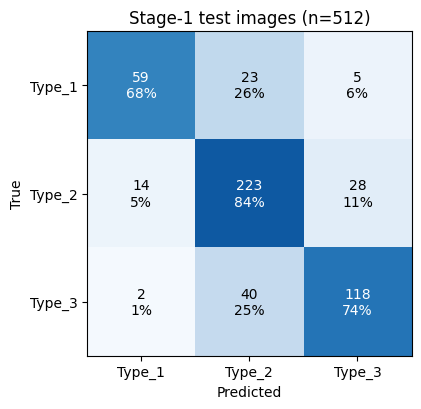

In [8]:
def metrics(P, y):
    pred = P.argmax(1)
    rec = [((pred == k) & (y == k)).sum() / (y == k).sum() for k in L]
    return [log_loss(y, P, labels=L), accuracy_score(y, pred), *rec, roc_auc_score(y, P, multi_class="ovr")]
NAMES = ["logloss", "accuracy", "Type_1 recall", "Type_2 recall", "Type_3 recall", "macro AUC"]

def ci_table(P, y, B=2000, seed=42):
    rng = np.random.default_rng(seed); n = len(y); boot = []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if len(np.unique(y[i])) < 3: continue
        boot.append(metrics(P[i], y[i]))
    boot, pt = np.array(boot), metrics(P, y)
    rows = [dict(measure=nm, value=round(pt[j], 3), ci_low=round(np.percentile(boot[:, j], 2.5), 3),
                 ci_high=round(np.percentile(boot[:, j], 97.5), 3)) for j, nm in enumerate(NAMES)]
    return pd.DataFrame(rows)

res = ci_table(P, y)
print(f"Frozen ensemble on stage-1 test images (n={len(y)})")
print(res.to_string(index=False))
res.to_csv(f"{OUT}/stage1_results.csv", index=False)
print(classification_report(y, P.argmax(1), target_names=classes, digits=3))
cm = confusion_matrix(y, P.argmax(1), labels=L); print(cm)

print("\nthreshold | near: n, accuracy | far: n, accuracy, logloss")
rows = []
for thr in [8, 10, 12]:
    near = d["d_train"].values <= thr; far = ~near
    a_near = (P.argmax(1) == y)[near].mean() if near.any() else float("nan")
    ll_far = log_loss(y[far], P[far], labels=L) if far.sum() > 10 and len(np.unique(y[far])) == 3 else float("nan")
    a_far = (P.argmax(1) == y)[far].mean()
    print(f"<= {thr:2d}     | {near.sum():3d}, {a_near:.3f}     | {far.sum():3d}, {a_far:.3f}, {ll_far:.3f}")
    rows.append(dict(threshold=thr, near_n=int(near.sum()), near_acc=a_near, far_n=int(far.sum()), far_acc=a_far, far_logloss=ll_far))
pd.DataFrame(rows).round(3).to_csv(f"{OUT}/stage1_leakage_check.csv", index=False)

cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(classes); ax.set_yticks(range(3)); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Stage-1 test images (n={len(y)})")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]*100:.0f}%", ha="center", va="center", color="white" if cmn[i, j] > .5 else "black")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_stage1_confusion.png", dpi=200); plt.show()

mistakes: 112 of 512
mean confidence: correct 0.80 | wrong 0.68


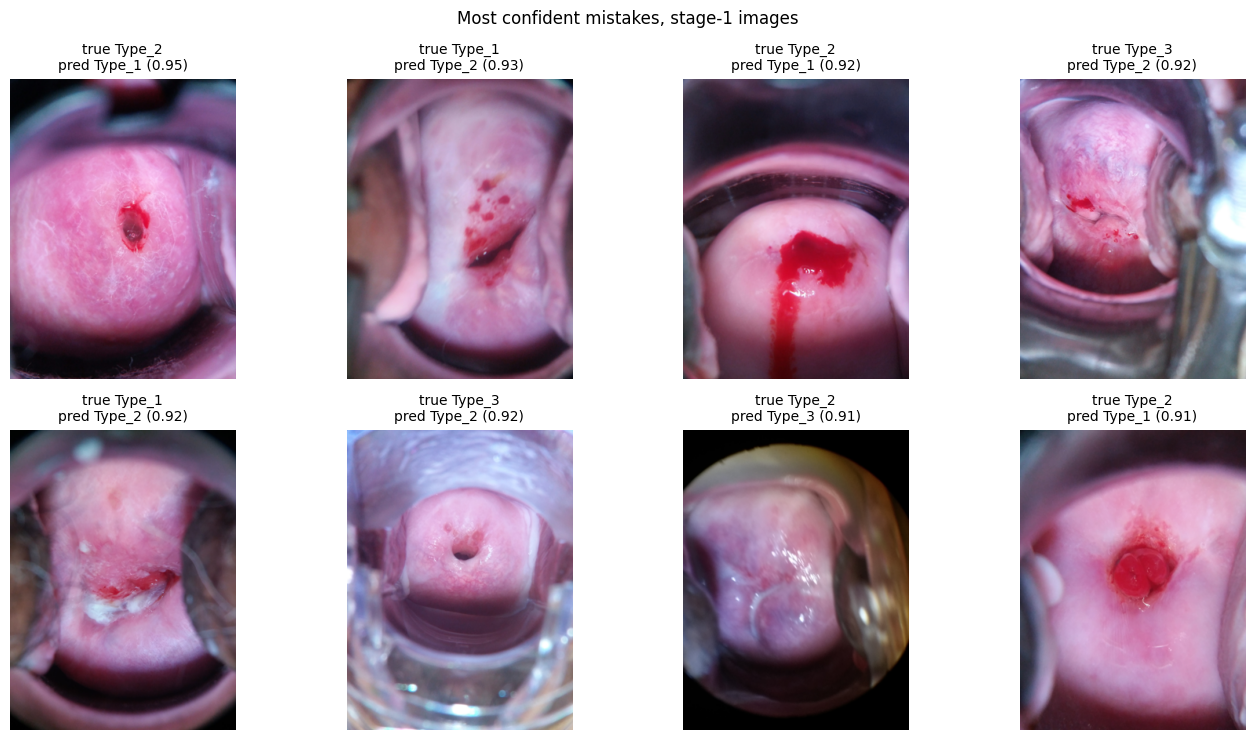

In [9]:
pred = P.argmax(1)
conf = P.max(1)
wrong = np.where(pred != y)[0]
print("mistakes:", len(wrong), "of", len(y))
print(f"mean confidence: correct {conf[pred == y].mean():.2f} | wrong {conf[wrong].mean():.2f}")

# the 8 mistakes where the model was most confident
worst = wrong[np.argsort(-conf[wrong])][:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), worst):
    with Image.open(os.path.join(TEST_DIR, d.loc[i, "file_name"])) as im:
        im = im.convert("RGB")
        im.thumbnail((384, 384))
        ax.imshow(im)
    ax.set_title(f"true {classes[y[i]]}\npred {classes[pred[i]]} ({conf[i]:.2f})", fontsize=10)
    ax.axis("off")
fig.suptitle("Most confident mistakes, stage-1 images")
plt.tight_layout()
plt.savefig(f"{OUT}/fig_stage1_confident_mistakes.png", dpi=150)
plt.show()

In [10]:
rows = []
for fn in tqdm(d["file_name"]):
    with Image.open(os.path.join(TEST_DIR, fn)) as im:
        w, h = im.size
        im = im.convert("RGB")
        im.thumbnail((384, 384))
        a = np.asarray(im).astype(np.float32)
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    rows.append(dict(
        width=w, height=h,
        brightness=a.mean(),
        red_frac=float(((r > 150) & (g < 80) & (b < 90)).mean()),   # strongly red pixels: rough blood proxy
        dark_frac=float((a.max(-1) < 25).mean()),                    # black border or vignette
        glare_frac=float((a.min(-1) > 235).mean()),                  # very bright pixels: glare
    ))
feat = pd.DataFrame(rows)
feat["correct"] = (pred == y)

cols = ["width", "height", "brightness", "red_frac", "dark_frac", "glare_frac"]
print(feat.groupby("correct")[cols].mean().round(3))

for col in ["red_frac", "glare_frac", "dark_frac"]:
    q = pd.qcut(feat[col].rank(method="first"), 4, labels=["lowest 25%", "2nd", "3rd", "highest 25%"])
    print(col, "-> accuracy by quarter:", feat.groupby(q, observed=True)["correct"].mean().round(3).to_dict())

feat.to_csv(f"{OUT}/stage1_error_features.csv", index=False)

100%|██████████| 512/512 [01:16<00:00,  6.66it/s]

            width    height  brightness  red_frac  dark_frac  glare_frac
correct                                                                 
False    2802.643  3638.357  106.859001     0.009      0.139       0.008
True     2806.065  3690.900  112.668999     0.020      0.114       0.008
red_frac -> accuracy by quarter: {'lowest 25%': 0.758, '2nd': 0.688, '3rd': 0.789, 'highest 25%': 0.891}
glare_frac -> accuracy by quarter: {'lowest 25%': 0.797, '2nd': 0.828, '3rd': 0.742, 'highest 25%': 0.758}
dark_frac -> accuracy by quarter: {'lowest 25%': 0.844, '2nd': 0.766, '3rd': 0.812, 'highest 25%': 0.703}
